# Ejercicio 7: Árboles de decisión

**Tópicos Selectos en Aprendizaje Maquinal — TP N°1: Algoritmos para Reconocimiento de Patrones**

En este notebook se resuelve el Ejercicio 7 de la guía: se construye un **árbol de decisión binario** para el problema de los partidos de tenis, primero siguiendo paso a paso el razonamiento "a mano" (con todas las cuentas), luego con un programa propio que crece árboles automáticamente, y finalmente extendiendo el programa a **atributos numéricos**.

| Inciso | Consigna | Idea central |
|:--|:--|:--|
| **1a** | Árbol a mano con entropía | En cada nodo se evalúan **todas** las preguntas binarias posibles y se elige la que más reduce la impureza |
| **1b** | Programa que crece árboles binarios | Mismo procedimiento, automatizado; se contrasta con el árbol a mano |
| **1c** | Cambiar la impureza | Entropía vs. Gini vs. error de clasificación |
| **2** | Atributos numéricos (Cuadro 2) | Las preguntas pasan a ser umbrales $x \le t$ |

**Contenido**

1. [Datos](#1.-Datos)
2. [Fundamentos](#2.-Fundamentos)
3. [Inciso 1a: construcción "a mano"](#3.-Inciso-1a:-construcción-%22a-mano%22)
4. [Inciso 1b: programa que crece árboles](#4.-Inciso-1b:-programa-que-crece-árboles)
5. [Inciso 1c: otras impurezas](#5.-Inciso-1c:-otras-impurezas)
6. [Inciso 2: atributos numéricos](#6.-Inciso-2:-atributos-numéricos)
7. [Conclusiones](#7.-Conclusiones)

In [1]:
import itertools
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)
np.set_printoptions(precision=4, suppress=True)

---
## 1. Datos

El Cuadro 1 de la guía tiene $N=14$ días descritos por cuatro atributos **categóricos** (pronóstico, temperatura, humedad y viento) y la clase: se juega el partido (**P**) o se suspende (**N**).

In [2]:
filas = [
    ("soleado",  "calor",    "alta",   "no", "N"),
    ("soleado",  "calor",    "alta",   "si", "N"),
    ("nublado",  "calor",    "alta",   "no", "P"),
    ("lluvioso", "moderado", "alta",   "no", "P"),
    ("lluvioso", "frío",     "normal", "no", "P"),
    ("lluvioso", "frío",     "normal", "si", "N"),
    ("nublado",  "frío",     "normal", "si", "P"),
    ("soleado",  "moderado", "alta",   "no", "N"),
    ("soleado",  "frío",     "normal", "no", "P"),
    ("lluvioso", "moderado", "normal", "no", "P"),
    ("soleado",  "moderado", "normal", "si", "P"),
    ("nublado",  "moderado", "alta",   "si", "P"),
    ("nublado",  "calor",    "normal", "no", "P"),
    ("lluvioso", "moderado", "alta",   "si", "N"),
]
df = pd.DataFrame(filas, columns=["Pronóstico", "Temp", "Humedad", "Viento", "Juega"])
df.index = np.arange(1, 15)          # numeración del cuadro: 1..14
df.index.name = "#"

X1, y1 = df.drop(columns="Juega"), df["Juega"]
tipos1 = {a: "cat" for a in X1.columns}

display(df)
print("Clases:", y1.value_counts().to_dict())

,Pronóstico,Temp,Humedad,Viento,Juega
#,,,,,
1,soleado,calor,alta,no,N
2,soleado,calor,alta,si,N
3,nublado,calor,alta,no,P
4,lluvioso,moderado,alta,no,P
5,lluvioso,frío,normal,no,P
6,lluvioso,frío,normal,si,N
7,nublado,frío,normal,si,P
8,soleado,moderado,alta,no,N
9,soleado,frío,normal,no,P


Clases: {'P': 9, 'N': 5}


---
## 2. Fundamentos

### 2.1 Qué es un árbol de decisión

Un árbol de decisión clasifica una muestra haciéndole una **secuencia de preguntas** sobre sus atributos. Cada **nodo interno** contiene una pregunta, cada **rama** una respuesta y cada **hoja** una clase. En un árbol **binario** toda pregunta tiene solo dos respuestas (sí/no), que es lo que pide la consigna.

Las preguntas binarias posibles dependen del tipo de atributo:

- **Atributo categórico** con $k$ valores: se pregunta "¿el valor pertenece al subconjunto $S$?". Hay $2^{k-1}-1$ particiones distintas en dos grupos no vacíos. Para $k=2$ hay una sola (ej.: viento = no / viento = sí); para $k=3$ hay tres, que son siempre "un valor contra los otros dos" (ej.: pronóstico = nublado / pronóstico $\in$ {soleado, lluvioso}).
- **Atributo numérico**: se pregunta "¿$x \le t$?". Solo importa en qué lugar del orden de los datos cae el umbral, así que alcanza con probar el **punto medio entre cada par de valores consecutivos** distintos.

### 2.2 Impureza y ganancia

Para decidir qué pregunta es mejor se mide qué tan "mezcladas" están las clases en un nodo $N$ mediante una **medida de impureza** $i(N)$, que debe ser $0$ si el nodo es puro y máxima si las clases están equiprobables. Con $P(\omega_j)$ la fracción de muestras de clase $j$ en el nodo:

$$
\begin{aligned}
\text{Entropía:}\quad & i_E(N) = -\sum_j P(\omega_j)\log_2 P(\omega_j) \\
\text{Gini:}\quad & i_G(N) = 1-\sum_j P(\omega_j)^2 \\
\text{Error de clasificación:}\quad & i_M(N) = 1-\max_j P(\omega_j)
\end{aligned}
$$

Una pregunta que parte el nodo $N$ en $N_L$ (respuesta sí) y $N_R$ (respuesta no) produce una **reducción de impureza** (ganancia):

$$
\Delta i = i(N) - P_L\, i(N_L) - P_R\, i(N_R), \qquad P_L = \frac{|N_L|}{|N|},\; P_R=\frac{|N_R|}{|N|}.
$$

Con la entropía, $\Delta i$ es la **ganancia de información** (información mutua entre la respuesta y la clase).

### 2.3 Algoritmo (voraz, tipo CART/ID3)

1. Si el nodo es puro (o no se puede dividir más), es una **hoja** y se le asigna la clase mayoritaria.
2. Si no, se evalúan **todas** las preguntas binarias posibles sobre **todos** los atributos y se elige la de mayor $\Delta i$.
3. Se divide el nodo y se repite recursivamente en cada hijo.

Dos observaciones importantes:

- Es un algoritmo **voraz** (*greedy*): elige lo mejor para el nodo actual sin mirar hacia adelante, así que no garantiza el árbol más chico posible.
- Puede haber **empates** de ganancia. En ese caso cualquier opción es válida; para tener resultados reproducibles el programa usa un criterio fijo (el primer atributo en el orden de las columnas) y registra los empates.

### 2.4 Cómo se comparan las impurezas

La figura muestra las tres medidas para dos clases como función de la proporción $p$ de una de ellas. Las dos últimas están multiplicadas por 2 para que las tres tengan el mismo máximo (1) y se puedan comparar las formas.

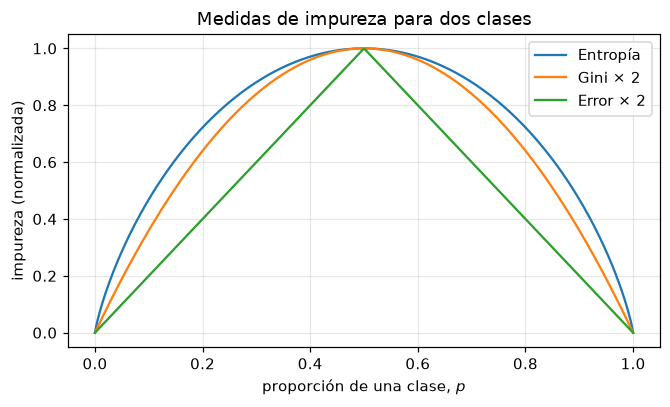

In [3]:
p = np.linspace(1e-9, 1 - 1e-9, 400)
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.plot(p, -(p * np.log2(p) + (1 - p) * np.log2(1 - p)), label="Entropía")
ax.plot(p, 2 * (1 - p**2 - (1 - p)**2), label="Gini × 2")
ax.plot(p, 2 * (1 - np.maximum(p, 1 - p)), label="Error × 2")
ax.set(xlabel="proporción de una clase, $p$", ylabel="impureza (normalizada)",
       title="Medidas de impureza para dos clases")
ax.legend()
plt.tight_layout(); plt.show()

Entropía y Gini son **suaves y estrictamente cóncavas**; el error de clasificación es lineal por tramos (no es estrictamente cóncavo). Esto último tiene una consecuencia práctica que se verá en el inciso 1c: hay divisiones que mejoran la pureza de los hijos pero **no reducen el error**, y el error no las distingue.

---
## 3. Inciso 1a: construcción "a mano"

Se desarrolla el árbol nodo por nodo, tal como se haría en papel. Para cada nodo hay que:

1. Contar cuántas muestras de cada clase hay y calcular su **entropía**.
2. Listar **todas las preguntas binarias** posibles y, para cada una, contar las clases a cada lado y calcular $\Delta i$.
3. Elegir la de mayor ganancia, partir el nodo y repetir en los hijos hasta llegar a nodos puros.

Para que las cuentas queden a la vista, las celdas de código siguientes solo hacen aritmética (contar y evaluar la fórmula); no crecen el árbol solas. La automatización viene en el inciso 1b.

### 3.1 Herramientas de cálculo

In [4]:
CLASES = ["P", "N"]


def impureza(conteos, tipo="entropia"):
    '''Impureza de un nodo a partir de los conteos de cada clase.'''
    n = sum(conteos)
    if n == 0:
        return 0.0
    q = np.array([c / n for c in conteos if c > 0])
    if tipo == "entropia":
        return float(-(q * np.log2(q)).sum()) + 0.0
    if tipo == "gini":
        return float(1 - (q**2).sum())
    if tipo == "error":
        return float(1 - q.max())
    raise ValueError(tipo)


def conteos_de(y):
    return [int((y == c).sum()) for c in CLASES]


def generar_particiones(sub, atributos, tipos):
    '''Todas las preguntas binarias posibles sobre el subconjunto `sub`.
    Devuelve una lista de (atributo, tipo, condición, máscara de la rama "sí").'''
    out = []
    for a in atributos:
        col = sub[a]
        if tipos[a] == "num":
            v = np.sort(col.unique())
            for u, w in zip(v[:-1], v[1:]):
                t = (u + w) / 2
                out.append((a, "num", float(t), (col <= t).values))
        else:
            v = sorted(col.unique())
            for r in range(1, len(v) // 2 + 1):
                for S in itertools.combinations(v, r):
                    # con |S| = k/2 la partición (S, resto) y (resto, S) es la misma
                    if 2 * r == len(v) and v[0] not in S:
                        continue
                    out.append((a, "cat", frozenset(S), col.isin(S).values))
    return out


def texto_pregunta(a, tipo, cond):
    if tipo == "num":
        return f"{a} ≤ {cond:g}"
    if len(cond) == 1:
        return f"{a} = {next(iter(cond))}"
    return f"{a} ∈ {{{', '.join(sorted(cond))}}}"


def evaluar(sub, y, atributos, tipos, tipo_imp="entropia"):
    '''Evalúa todas las preguntas posibles en un nodo. Devuelve una lista de dicts con la ganancia.'''
    n = len(y)
    i0 = impureza(conteos_de(y), tipo_imp)
    res = []
    for a, tp, cond, mask in generar_particiones(sub, atributos, tipos):
        cL, cR = conteos_de(y[mask]), conteos_de(y[~mask])
        iL, iR = impureza(cL, tipo_imp), impureza(cR, tipo_imp)
        nL, nR = sum(cL), sum(cR)
        res.append(dict(atributo=a, tipo=tp, cond=cond, mask=mask, cL=cL, cR=cR, iL=iL, iR=iR,
                        ganancia=round(i0 - nL / n * iL - nR / n * iR, 12) + 0.0))
    return i0, res


def tabla_candidatos(sub, y, atributos, tipos, tipo_imp="entropia", top=None):
    i0, res = evaluar(sub, y, atributos, tipos, tipo_imp)
    gmax = max(r["ganancia"] for r in res)
    filas_t = []
    for r in res:
        filas_t.append({
            "Pregunta (rama sí)": texto_pregunta(r["atributo"], r["tipo"], r["cond"]),
            "sí (P/N)": f"{r['cL'][0]}/{r['cL'][1]}",
            "no (P/N)": f"{r['cR'][0]}/{r['cR'][1]}",
            "i(sí)": r["iL"], "i(no)": r["iR"],
            "Δi": r["ganancia"],
            "máx": "◀" if r["ganancia"] > gmax - 1e-9 else "",
        })
    t = pd.DataFrame(filas_t).sort_values("Δi", ascending=False, kind="stable").reset_index(drop=True)
    t.index = t.index + 1
    return i0, (t if top is None else t.head(top)), res


def analizar_nodo(nombre, sub, atributos=None, tipos=tipos1, tipo_imp="entropia", top=None):
    y = df.loc[sub.index, "Juega"] if "Juega" in df else None
    atributos = atributos or [c for c in sub.columns if c != "Juega"]
    c = conteos_de(y)
    print(f"{nombre}: muestras {list(sub.index)}")
    print(f"  n = {sum(c)},  P = {c[0]},  N = {c[1]},  i(N) = {impureza(c, tipo_imp):.4f}")
    if impureza(c, tipo_imp) == 0:
        print("  → nodo puro: HOJA")
        return None
    i0, t, res = tabla_candidatos(sub[atributos], y, atributos, tipos, tipo_imp, top)
    display(t.style.format({"i(sí)": "{:.4f}", "i(no)": "{:.4f}", "Δi": "{:.4f}"}))
    return res


def detalle(res, texto, tipo_imp="entropia"):
    '''Imprime la cuenta de Δi de una pregunta, con todos los números.'''
    r = next(r for r in res if texto_pregunta(r["atributo"], r["tipo"], r["cond"]) == texto)
    cL, cR = r["cL"], r["cR"]
    c0 = [a + b for a, b in zip(cL, cR)]
    n, nL, nR = sum(c0), sum(cL), sum(cR)

    def ent(c):
        n_ = sum(c)
        partes = [f"{k}/{n_}·log2({k}/{n_})" for k in c if k > 0]
        return "-(" + " + ".join(partes) + ")" if partes else "0"

    print(f"Pregunta: {texto}")
    print(f"  i(N)   = {ent(c0)} = {impureza(c0, tipo_imp):.4f}")
    print(f"  i(sí)  = {ent(cL)} = {r['iL']:.4f}      ({nL} muestras: P={cL[0]}, N={cL[1]})")
    print(f"  i(no)  = {ent(cR)} = {r['iR']:.4f}      ({nR} muestras: P={cR[0]}, N={cR[1]})")
    print(f"  Δi = i(N) - {nL}/{n}·i(sí) - {nR}/{n}·i(no)"
          f" = {impureza(c0, tipo_imp):.4f} - {nL/n:.4f}·{r['iL']:.4f} - {nR/n:.4f}·{r['iR']:.4f}"
          f" = {r['ganancia']:.4f}")

La entropía de un nodo con $n_P$ muestras de la clase P y $n_N$ de la clase N es
$i_E = -\frac{n_P}{n}\log_2\frac{n_P}{n} - \frac{n_N}{n}\log_2\frac{n_N}{n}$, con la convención $0\log_2 0 = 0$. Dos casos útiles para calcular a mano: un nodo puro tiene $i_E=0$ y un nodo con partes iguales tiene $i_E=1$.

### 3.2 Nodo raíz (las 14 muestras)

El nodo raíz tiene 9 muestras P y 5 N, por lo que
$$i_E(\text{raíz}) = -\tfrac{9}{14}\log_2\tfrac{9}{14}-\tfrac{5}{14}\log_2\tfrac{5}{14}\approx 0.940.$$

Hay $3+3+1+1 = 8$ preguntas binarias posibles: pronóstico (3 particiones), temperatura (3), humedad (1) y viento (1).

In [5]:
res0 = analizar_nodo("Nodo 0 (raíz)", X1)

Nodo 0 (raíz): muestras [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
  n = 14,  P = 9,  N = 5,  i(N) = 0.9403


,Pregunta (rama sí),sí (P/N),no (P/N),i(sí),i(no),Δi,máx
1,Pronóstico = nublado,4/0,5/5,0.0000,1.0000,0.2260,◀
2,Humedad = alta,3/4,6/1,0.9852,0.5917,0.1518,
3,Pronóstico = soleado,2/3,7/2,0.9710,0.7642,0.1022,
4,Viento = no,6/2,3/3,0.8113,1.0000,0.0481,
5,Temp = calor,2/2,7/3,1.0000,0.8813,0.0251,
6,Temp = frío,3/1,6/4,0.8113,0.9710,0.0150,
7,Pronóstico = lluvioso,3/2,6/3,0.9710,0.9183,0.0032,
8,Temp = moderado,4/2,5/3,0.9183,0.9544,0.0013,


**Observaciones.**

- **Ganancia de cada pregunta.** La mejor es **Pronóstico = nublado** con $\Delta i = 0.2260$; le siguen Humedad = alta (0.1518) y Pronóstico = soleado (0.1022). Las preguntas sobre temperatura y "pronóstico = lluvioso" casi no informan (menos de 0.03).
- **Por qué gana "nublado".** Aísla un nodo **puro** (las 4 muestras nubladas son todas P, entropía 0), y deja el resto (5 P y 5 N) en el peor caso posible ($i_E=1$). Humedad = alta, en cambio, no produce ningún nodo puro, aunque reparte mejor las muestras (7 y 7).
- **Cuenta a mano de las dos mejores.** Con las fórmulas de la celda anterior:
  $\Delta i(\text{nublado}) = 0.9403 - \tfrac{4}{14}\cdot 0 - \tfrac{10}{14}\cdot 1 = 0.2260$ y
  $\Delta i(\text{humedad alta}) = 0.9403 - \tfrac{7}{14}\cdot 0.9852 - \tfrac{7}{14}\cdot 0.5917 = 0.1518$.
- **No hay empate** en la raíz: la mejor pregunta es única.

In [6]:
detalle(res0, "Pronóstico = nublado")
print()
detalle(res0, "Humedad = alta")

Pregunta: Pronóstico = nublado
  i(N)   = -(9/14·log2(9/14) + 5/14·log2(5/14)) = 0.9403
  i(sí)  = -(4/4·log2(4/4)) = 0.0000      (4 muestras: P=4, N=0)
  i(no)  = -(5/10·log2(5/10) + 5/10·log2(5/10)) = 1.0000      (10 muestras: P=5, N=5)
  Δi = i(N) - 4/14·i(sí) - 10/14·i(no) = 0.9403 - 0.2857·0.0000 - 0.7143·1.0000 = 0.2260

Pregunta: Humedad = alta
  i(N)   = -(9/14·log2(9/14) + 5/14·log2(5/14)) = 0.9403
  i(sí)  = -(3/7·log2(3/7) + 4/7·log2(4/7)) = 0.9852      (7 muestras: P=3, N=4)
  i(no)  = -(6/7·log2(6/7) + 1/7·log2(1/7)) = 0.5917      (7 muestras: P=6, N=1)
  Δi = i(N) - 7/14·i(sí) - 7/14·i(no) = 0.9403 - 0.5000·0.9852 - 0.5000·0.5917 = 0.1518


**Comparación con una división no binaria.** Si se permitiera dividir en **tres hijos** a la vez (uno por valor de pronóstico, como en ID3), la ganancia de pronóstico sería $0.2467$, algo mayor que la de la mejor pregunta binaria ($0.2260$), porque también separa "soleado" de "lluvioso". Con la restricción binaria, ese refinamiento debe hacerse más abajo en el árbol, con otras preguntas. Para los atributos de dos valores no hay diferencia: humedad (0.1518) y viento (0.0481) valen lo mismo en ambos esquemas.

In [7]:
def ganancia_multicamino(sub, y, atributo, tipo_imp="entropia"):
    '''Ganancia de dividir en TODOS los valores del atributo a la vez (árbol no binario, estilo ID3).'''
    n = len(y)
    g = impureza(conteos_de(y), tipo_imp)
    for v in sub[atributo].unique():
        yv = y[sub[atributo] == v]
        g -= len(yv) / n * impureza(conteos_de(yv), tipo_imp)
    return g


print("Ganancia con división multicamino (un hijo por valor):")
for a in X1.columns:
    print(f"  {a:11s} {ganancia_multicamino(X1, y1, a):.4f}")

Ganancia con división multicamino (un hijo por valor):
  Pronóstico  0.2467
  Temp        0.0292
  Humedad     0.1518
  Viento      0.0481


### 3.3 Nodo 1: lo que queda tras separar "nublado"

Con la raíz "¿pronóstico = nublado?", la rama **sí** contiene las muestras 3, 7, 12 y 13, todas de clase P: es una **hoja pura** (P). La rama **no** reúne las 10 muestras restantes (soleado y lluvioso), con 5 P y 5 N, así que su entropía es máxima ($i_E=1$) y hay que seguir dividiendo.

In [8]:
n1 = X1[X1["Pronóstico"] != "nublado"]
print("Hoja izquierda (nublado):", list(X1[X1["Pronóstico"] == "nublado"].index), "→ clases presentes:", list(y1[X1["Pronóstico"] == "nublado"].unique()))
print()
res1 = analizar_nodo("Nodo 1", n1)

Hoja izquierda (nublado): [3, 7, 12, 13] → clases presentes: ['P']

Nodo 1: muestras [1, 2, 4, 5, 6, 8, 9, 10, 11, 14]
  n = 10,  P = 5,  N = 5,  i(N) = 1.0000


,Pregunta (rama sí),sí (P/N),no (P/N),i(sí),i(no),Δi,máx
1,Humedad = alta,1/4,4/1,0.7219,0.7219,0.2781,◀
2,Temp = calor,0/2,5/3,0.0000,0.9544,0.2365,
3,Viento = no,4/2,1/3,0.9183,0.8113,0.1245,
4,Temp = frío,2/1,3/4,0.9183,0.9852,0.0349,
5,Pronóstico = lluvioso,3/2,2/3,0.9710,0.9710,0.0290,
6,Temp = moderado,3/2,2/3,0.9710,0.9710,0.0290,


**Observaciones.**

- Gana **Humedad = alta** con $\Delta i = 0.2781$: reparte las 10 muestras en dos grupos de 5, uno con 1 P y 4 N (humedad alta) y otro con 4 P y 1 N (humedad normal), con entropía $0.7219$ cada uno.
- El segundo lugar es **Temp = calor** ($0.2365$): aísla las dos muestras calurosas (1 y 2), ambas N, pero deja el resto bastante mezclado (5 P y 3 N).
- Otra vez la mejor pregunta es única, así que no hay ambigüedad en este nodo.

In [9]:
detalle(res1, "Humedad = alta")

Pregunta: Humedad = alta
  i(N)   = -(5/10·log2(5/10) + 5/10·log2(5/10)) = 1.0000
  i(sí)  = -(1/5·log2(1/5) + 4/5·log2(4/5)) = 0.7219      (5 muestras: P=1, N=4)
  i(no)  = -(4/5·log2(4/5) + 1/5·log2(1/5)) = 0.7219      (5 muestras: P=4, N=1)
  Δi = i(N) - 5/10·i(sí) - 5/10·i(no) = 1.0000 - 0.5000·0.7219 - 0.5000·0.7219 = 0.2781


### 3.4 Nodos 2 y 3: las dos ramas de la humedad

Se separa el nodo 1 según la humedad: el nodo 2 (humedad alta) y el nodo 3 (humedad normal), ambos con 5 muestras y la misma entropía.

In [10]:
n2 = n1[n1["Humedad"] == "alta"]
n3 = n1[n1["Humedad"] == "normal"]
res2 = analizar_nodo("Nodo 2 (humedad alta)", n2.drop(columns="Humedad"), tipos={a: "cat" for a in X1.columns})
print()
res3 = analizar_nodo("Nodo 3 (humedad normal)", n3.drop(columns="Humedad"), tipos={a: "cat" for a in X1.columns})

Nodo 2 (humedad alta): muestras [1, 2, 4, 8, 14]
  n = 5,  P = 1,  N = 4,  i(N) = 0.7219


,Pregunta (rama sí),sí (P/N),no (P/N),i(sí),i(no),Δi,máx
1,Pronóstico = lluvioso,1/1,0/3,1.0000,0.0000,0.3219,◀
2,Temp = calor,0/2,1/2,0.0000,0.9183,0.1710,
3,Viento = no,1/2,0/2,0.9183,0.0000,0.1710,



Nodo 3 (humedad normal): muestras [5, 6, 9, 10, 11]
  n = 5,  P = 4,  N = 1,  i(N) = 0.7219


,Pregunta (rama sí),sí (P/N),no (P/N),i(sí),i(no),Δi,máx
1,Viento = no,3/0,1/1,0.0000,1.0000,0.3219,◀
2,Pronóstico = lluvioso,2/1,2/0,0.9183,0.0000,0.1710,
3,Temp = frío,2/1,2/0,0.9183,0.0000,0.1710,


**Observaciones.**

- **Nodo 2 (humedad alta; 1 P y 4 N).** La mejor pregunta es **Pronóstico = lluvioso** ($\Delta i=0.3219$): separa un nodo con las muestras 4 (P) y 14 (N) del resto, que son las tres muestras soleadas (1, 2, 8), todas N. Es única (las siguientes valen $0.1710$).
- **Nodo 3 (humedad normal; 4 P y 1 N).** La mejor es **Viento = no** ($\Delta i=0.3219$): deja un nodo puro con las muestras 5, 9 y 10 (P) y otro con las muestras 6 (N) y 11 (P). También es única (las siguientes, Pronóstico = lluvioso y Temp = frío, valen $0.1710$).
- En ambos nodos se descartó el atributo humedad, ya fijado en el nivel anterior: dentro del nodo es constante y no puede dividirlo.

### 3.5 Nodos 4 y 5: los dos nodos que quedan con mezcla

- El **nodo 4** (humedad alta y lluvioso) tiene las muestras 4 (P) y 14 (N).
- El **nodo 5** (humedad normal y viento sí) tiene las muestras 6 (N) y 11 (P).
- Además, hay hojas puras: *soleado con humedad alta* (muestras 1, 2, 8: todas N) y *humedad normal con viento no* (muestras 5, 9, 10: todas P).

In [11]:
n4 = n2[n2["Pronóstico"] == "lluvioso"]
n5 = n3[n3["Viento"] == "si"]
print("Hoja (humedad alta, soleado):", list(n2[n2["Pronóstico"] == "soleado"].index), "→", list(y1[n2[n2["Pronóstico"] == "soleado"].index].unique()))
print("Hoja (humedad normal, viento no):", list(n3[n3["Viento"] == "no"].index), "→", list(y1[n3[n3["Viento"] == "no"].index].unique()))
print()
res4 = analizar_nodo("Nodo 4 (alta, lluvioso)", n4.drop(columns=["Humedad", "Pronóstico"]), tipos={a: "cat" for a in X1.columns})
print()
res5 = analizar_nodo("Nodo 5 (normal, viento sí)", n5.drop(columns=["Humedad", "Viento"]), tipos={a: "cat" for a in X1.columns})

Hoja (humedad alta, soleado): [1, 2, 8] → ['N']
Hoja (humedad normal, viento no): [5, 9, 10] → ['P']

Nodo 4 (alta, lluvioso): muestras [4, 14]
  n = 2,  P = 1,  N = 1,  i(N) = 1.0000


,Pregunta (rama sí),sí (P/N),no (P/N),i(sí),i(no),Δi,máx
1,Viento = no,1/0,0/1,0.0000,0.0000,1.0000,◀



Nodo 5 (normal, viento sí): muestras [6, 11]
  n = 2,  P = 1,  N = 1,  i(N) = 1.0000


,Pregunta (rama sí),sí (P/N),no (P/N),i(sí),i(no),Δi,máx
1,Pronóstico = lluvioso,0/1,1/0,0.0000,0.0000,1.0000,◀
2,Temp = frío,0/1,1/0,0.0000,0.0000,1.0000,◀


**Observaciones.**

- **Nodo 4** (muestras 4 y 14): solo la pregunta sobre el viento las distingue (la temperatura es *moderado* en ambas), con $\Delta i=1$. La muestra 4 (viento no) es P y la 14 (viento sí) es N.
- **Nodo 5** (muestras 6 y 11): hay un **empate exacto** entre *Pronóstico = lluvioso* y *Temp = frío*, ambas con $\Delta i=1$, porque tanto una como otra separan las dos muestras (la 6 es lluviosa y fría; la 11, soleada y moderada). Cualquiera de las dos es válida y da árboles que clasifican igual los datos. Aquí se eligió el pronóstico (primer atributo en el orden de las columnas).
- Es el **único empate** de todo el desarrollo: en el resto de los nodos la mejor pregunta es única.

### 3.6 Árbol resultante

Reuniendo todas las decisiones, el árbol obtenido con entropía es (la rama de la izquierda es la respuesta **sí**):

```
¿Pronóstico = nublado?
├─ sí → P                                       (muestras 3, 7, 12, 13)
└─ no → ¿Humedad = alta?
        ├─ sí → ¿Pronóstico = lluvioso?
        │       ├─ sí → ¿Viento = no?
        │       │       ├─ sí → P               (muestra 4)
        │       │       └─ no → N               (muestra 14)
        │       └─ no → N                       (muestras 1, 2, 8)
        └─ no → ¿Viento = no?
                ├─ sí → P                       (muestras 5, 9, 10)
                └─ no → ¿Pronóstico = lluvioso?  (o ¿Temp = frío?, empate)
                        ├─ sí → N               (muestra 6)
                        └─ no → P               (muestra 11)
```

Tiene 6 nodos de decisión y **7 hojas** (profundidad 4), y clasifica correctamente las 14 muestras.

> 📌 **Aquí va tu esquema.** Insertá la imagen del árbol que armaste a mano, por ejemplo con `![Árbol hecho a mano](ej7_arbol_mano.png)`, y compará con el de arriba. Si tu árbol difiere, el único lugar donde una diferencia es razonable es el **empate de ganancia** del nodo 5 (pronóstico o temperatura, ambos marcados con ◀); en todos los demás nodos la mejor pregunta es única, y escribir sí/no al revés no cambia el árbol. Una diferencia en otro lado sería señal de revisar las cuentas.

---
## 4. Inciso 1b: programa que crece árboles

Se automatiza el procedimiento anterior en una clase `ArbolBinario`. Las decisiones de diseño son:

- **Atributos categóricos y numéricos** (los numéricos se usan en el inciso 2): se indica el tipo de cada atributo con un diccionario.
- **Impureza intercambiable**: `"entropia"`, `"gini"` o `"error"`.
- **Desempates**: se prioriza el primer atributo de la lista `prioridad` (por defecto, el orden de las columnas), y dentro de un atributo, la primera pregunta generada. Cada nodo guarda la lista de empates para poder auditarlos.
- **Criterios de parada** opcionales (`max_prof`, `min_muestras_div`, `min_ganancia`). Por defecto el árbol crece hasta que todas las hojas son puras.
- Un valor categórico no visto en el entrenamiento va por la rama **no** al predecir.

In [12]:
class ArbolBinario:
    def __init__(self, impureza="entropia", prioridad=None, max_prof=None,
                 min_muestras_div=2, min_ganancia=0.0):
        self.impureza = impureza
        self.prioridad = prioridad
        self.max_prof = max_prof
        self.min_muestras_div = min_muestras_div
        self.min_ganancia = min_ganancia

    def fit(self, X, y, tipos):
        self.tipos = tipos
        self.atributos = list(self.prioridad) if self.prioridad else list(X.columns)
        self.raiz = self._crecer(X, y, 0)
        return self

    def _crecer(self, X, y, prof):
        c = conteos_de(y)
        nodo = dict(n=len(y), conteo=dict(zip(CLASES, c)), clase=CLASES[int(np.argmax(c))],
                    impureza=impureza(c, self.impureza), split=None)
        if (nodo["impureza"] == 0 or len(y) < self.min_muestras_div
                or (self.max_prof is not None and prof >= self.max_prof)):
            return nodo
        _, res = evaluar(X, y, self.atributos, self.tipos, self.impureza)
        if not res:                       # filas idénticas con clases distintas
            return nodo
        gmax = max(r["ganancia"] for r in res)
        if gmax < self.min_ganancia - 1e-12:
            return nodo
        # primer candidato con la ganancia máxima (las preguntas se generan por orden de prioridad)
        mejor = next(r for r in res if r["ganancia"] > gmax - 1e-9)
        empates = [texto_pregunta(r["atributo"], r["tipo"], r["cond"])
                   for r in res if r["ganancia"] > gmax - 1e-9]
        nodo["split"] = dict(atributo=mejor["atributo"], tipo=mejor["tipo"], cond=mejor["cond"],
                             ganancia=mejor["ganancia"], empates=empates)
        m = mejor["mask"]
        nodo["izq"] = self._crecer(X[m], y[m], prof + 1)
        nodo["der"] = self._crecer(X[~m], y[~m], prof + 1)
        return nodo

    def _predecir_fila(self, fila):
        nodo = self.raiz
        while nodo["split"] is not None:
            s = nodo["split"]
            v = fila[s["atributo"]]
            va_izq = (v <= s["cond"]) if s["tipo"] == "num" else (v in s["cond"])
            nodo = nodo["izq"] if va_izq else nodo["der"]
        return nodo["clase"]

    def predecir(self, X):
        return np.array([self._predecir_fila(f) for _, f in X.iterrows()])


# ---------- utilidades para inspeccionar / dibujar ----------
def hojas(n):
    return 1 if n["split"] is None else hojas(n["izq"]) + hojas(n["der"])


def profundidad(n):
    return 0 if n["split"] is None else 1 + max(profundidad(n["izq"]), profundidad(n["der"]))


def a_tupla(n):
    '''Forma canónica para comparar árboles.'''
    if n["split"] is None:
        return n["clase"]
    s = n["split"]
    cond = s["cond"] if s["tipo"] == "num" else set(s["cond"])
    return (s["atributo"], cond, a_tupla(n["izq"]), a_tupla(n["der"]))


def imprimir(n, prefijo="", etiqueta="", mostrar_empates=True):
    cnt = f"[P={n['conteo']['P']}, N={n['conteo']['N']}]"
    if n["split"] is None:
        print(f"{prefijo}{etiqueta}→ {n['clase']}  {cnt}")
        return
    s = n["split"]
    extra = f"   (empate con: {', '.join(e for e in s['empates'] if e != texto_pregunta(s['atributo'], s['tipo'], s['cond']))})" \
        if mostrar_empates and len(s["empates"]) > 1 else ""
    print(f"{prefijo}{etiqueta}¿{texto_pregunta(s['atributo'], s['tipo'], s['cond'])}?  {cnt}  Δi={s['ganancia']:.4f}{extra}")
    imprimir(n["izq"], prefijo + "    ", "sí: ", mostrar_empates)
    imprimir(n["der"], prefijo + "    ", "no: ", mostrar_empates)


COLOR_CLASE = {"P": "#cfe8cf", "N": "#f4cccc"}


def dibujar_arbol(raiz, ax=None, titulo=None):
    pos, cont = {}, [0]

    def layout(n, prof):
        if n["split"] is None:
            x = cont[0]; cont[0] += 1
        else:
            x = (layout(n["izq"], prof + 1) + layout(n["der"], prof + 1)) / 2
        pos[id(n)] = (x, -prof)
        return x

    layout(raiz, 0)
    nh, prof_max = hojas(raiz), profundidad(raiz)
    if ax is None:
        _, ax = plt.subplots(figsize=(max(6, 1.8 * nh), 1.7 * (prof_max + 1) + 0.6))

    def dibujar(n):
        x, y = pos[id(n)]
        cnt = f"P={n['conteo']['P']}  N={n['conteo']['N']}"
        if n["split"] is None:
            ax.text(x, y, f"{n['clase']}\n{cnt}", ha="center", va="center", fontsize=8.5,
                    bbox=dict(boxstyle="round,pad=0.35", fc=COLOR_CLASE[n["clase"]], ec="gray"))
            return
        s = n["split"]
        ax.text(x, y, f"¿{texto_pregunta(s['atributo'], s['tipo'], s['cond'])}?\n{cnt}", ha="center",
                va="center", fontsize=8.5, bbox=dict(boxstyle="round,pad=0.35", fc="#e8eefb", ec="gray"))
        for hijo, lab in ((n["izq"], "sí"), (n["der"], "no")):
            xh, yh = pos[id(hijo)]
            ax.plot([x, xh], [y - 0.17, yh + 0.2], color="gray", lw=1, zorder=0)
            ax.text((x + xh) / 2, (y + yh) / 2 + 0.03, lab, ha="center", va="center", fontsize=8,
                    color="dimgray", bbox=dict(fc="white", ec="none", pad=0.5))
            dibujar(hijo)

    dibujar(raiz)
    ax.set_xlim(-0.7, nh - 0.3); ax.set_ylim(-prof_max - 0.55, 0.55)
    ax.axis("off")
    if titulo:
        ax.set_title(titulo, fontsize=10)
    return ax


def exactitud(arbol, X, y):
    return float((arbol.predecir(X) == y.values).mean())


def loo(crear, X, y, tipos):
    '''Exactitud leave-one-out: se entrena sin la muestra i y se predice esa muestra.'''
    ok = 0
    for i in range(len(X)):
        tr = np.arange(len(X)) != i
        m = crear().fit(X[tr], y[tr], tipos)
        ok += m.predecir(X.iloc[[i]])[0] == y.iloc[i]
    return ok / len(X)

### 4.1 Árbol generado automáticamente (entropía)

¿Pronóstico = nublado?  [P=9, N=5]  Δi=0.2260
    sí: → P  [P=4, N=0]
    no: ¿Humedad = alta?  [P=5, N=5]  Δi=0.2781
        sí: ¿Pronóstico = lluvioso?  [P=1, N=4]  Δi=0.3219
            sí: ¿Viento = no?  [P=1, N=1]  Δi=1.0000
                sí: → P  [P=1, N=0]
                no: → N  [P=0, N=1]
            no: → N  [P=0, N=3]
        no: ¿Viento = no?  [P=4, N=1]  Δi=0.3219
            sí: → P  [P=3, N=0]
            no: ¿Pronóstico = lluvioso?  [P=1, N=1]  Δi=1.0000   (empate con: Temp = frío)
                sí: → N  [P=0, N=1]
                no: → P  [P=1, N=0]

Hojas: 7   Profundidad: 4   Exactitud en entrenamiento: 100%


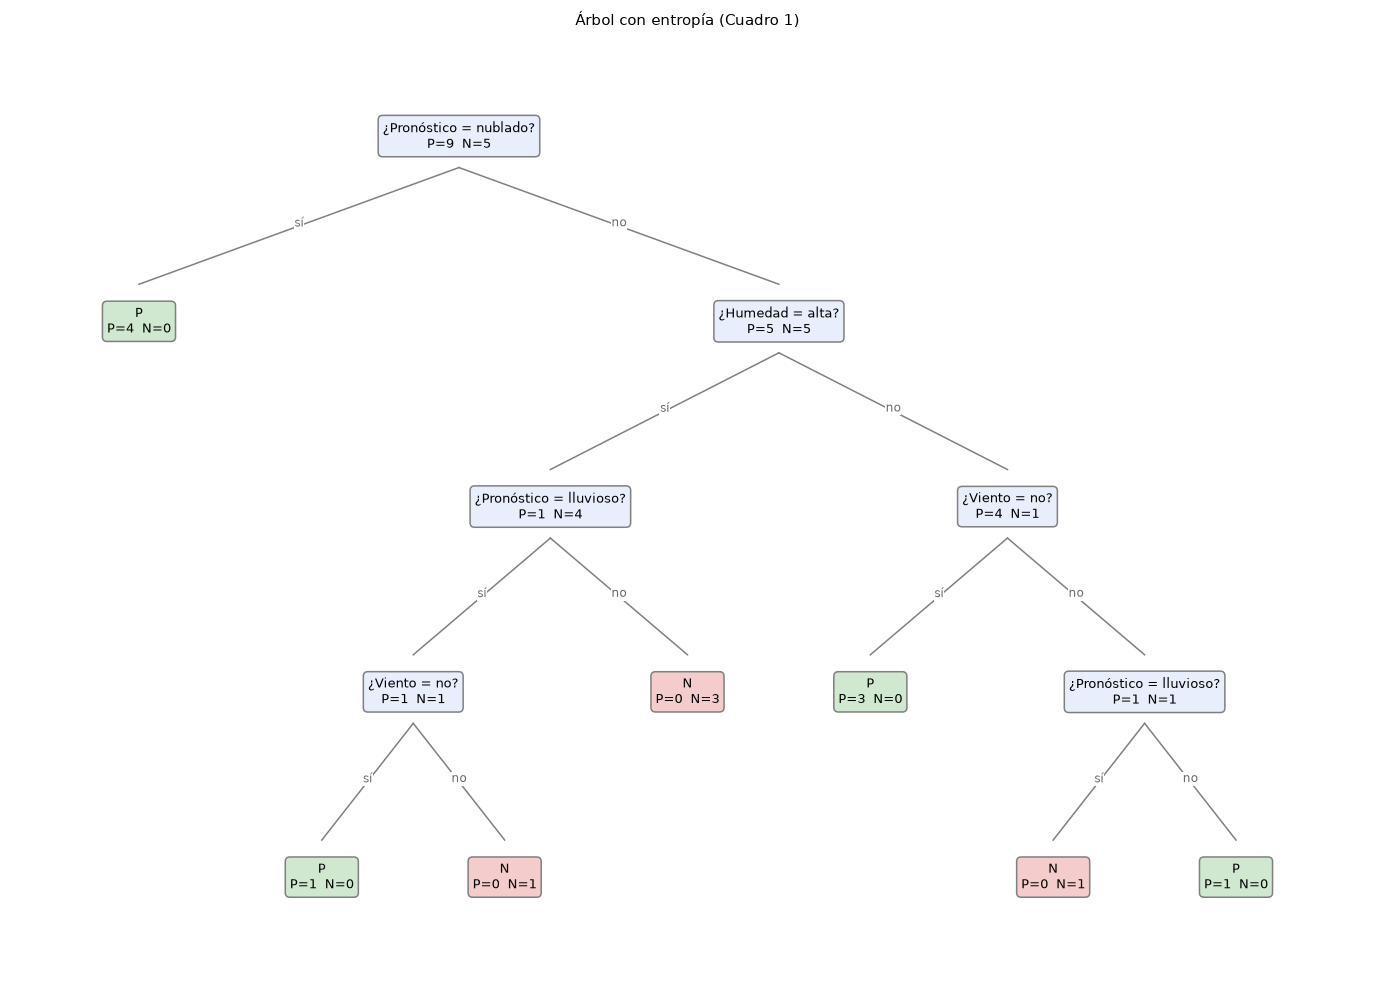

In [13]:
arbol_E = ArbolBinario("entropia").fit(X1, y1, tipos1)
imprimir(arbol_E.raiz)
print(f"\nHojas: {hojas(arbol_E.raiz)}   Profundidad: {profundidad(arbol_E.raiz)}   "
      f"Exactitud en entrenamiento: {exactitud(arbol_E, X1, y1):.0%}")
dibujar_arbol(arbol_E.raiz, titulo="Árbol con entropía (Cuadro 1)")
plt.tight_layout(); plt.show()

### 4.2 Contraste con el árbol construido a mano

Se codifica el árbol de la sección 3.6 como una estructura anidada `(atributo, subconjunto, rama_sí, rama_no)` y se lo compara con el que generó el programa:

In [14]:
arbol_mano = ("Pronóstico", {"nublado"},
              "P",
              ("Humedad", {"alta"},
               ("Pronóstico", {"lluvioso"}, ("Viento", {"no"}, "P", "N"), "N"),
               ("Viento", {"no"}, "P", ("Pronóstico", {"lluvioso"}, "N", "P"))))

print("¿Estructura idéntica a la del árbol a mano?", a_tupla(arbol_E.raiz) == arbol_mano)

# comprobación independiente de las ganancias: tabla del nodo raíz vs. el valor guardado por el programa
g_prog = arbol_E.raiz["split"]["ganancia"]
g_mano = max(r["ganancia"] for r in res0)
print(f"Ganancia de la raíz: programa = {g_prog:.6f},  tabla a mano = {g_mano:.6f}")

¿Estructura idéntica a la del árbol a mano? True
Ganancia de la raíz: programa = 0.226000,  tabla a mano = 0.226000


**Observaciones.** El árbol generado por el programa tiene **exactamente la misma estructura** que el desarrollado a mano (mismas preguntas, mismos nodos, mismas hojas) y la ganancia de la raíz coincide con la de la tabla calculada a mano ($0.2260$). Como la única decisión no unívoca es el empate del nodo 5, el programa y el cálculo manual solo podían discrepar ahí; el resultado es el mismo porque ambos desempatan con el mismo criterio.

### 4.3 Validación contra `scikit-learn`

`scikit-learn` no admite atributos categóricos directamente, pero si se codifican en variables binarias (*one-hot*), cada pregunta "atributo = valor" es exactamente una partición binaria "un valor contra el resto". Para atributos de 3 valores eso cubre **todas** las particiones, de modo que el árbol de `scikit-learn` con `criterion="entropy"` debería ser equivalente.

In [15]:
from sklearn.tree import DecisionTreeClassifier, export_text

Xd = pd.get_dummies(X1, dtype=int)
for seed in range(3):
    clf = DecisionTreeClassifier(criterion="entropy", random_state=seed).fit(Xd, y1)
    print(f"--- sklearn, random_state={seed}: hojas={clf.get_n_leaves()}, prof={clf.get_depth()}, "
          f"exactitud={clf.score(Xd, y1):.0%}, "
          f"misma predicción que el programa: {bool((clf.predict(Xd) == arbol_E.predecir(X1)).all())}")
clf = DecisionTreeClassifier(criterion="entropy", random_state=0).fit(Xd, y1)
print()
print(export_text(clf, feature_names=list(Xd.columns)))

# ganancia de la raíz según sklearn: impureza del padre - promedio ponderado de los hijos
t = clf.tree_
g_sk = t.impurity[0] - (t.n_node_samples[t.children_left[0]] * t.impurity[t.children_left[0]]
                         + t.n_node_samples[t.children_right[0]] * t.impurity[t.children_right[0]]) / t.n_node_samples[0]
print(f"Ganancia de la raíz según sklearn: {g_sk:.6f}  (programa: {g_prog:.6f});  pregunta: "
      f"{Xd.columns[t.feature[0]]} ≤ {t.threshold[0]}")

--- sklearn, random_state=0: hojas=7, prof=4, exactitud=100%, misma predicción que el programa: True
--- sklearn, random_state=1: hojas=7, prof=4, exactitud=100%, misma predicción que el programa: True
--- sklearn, random_state=2: hojas=7, prof=4, exactitud=100%, misma predicción que el programa: True

|--- Pronóstico_nublado <= 0.50
|   |--- Humedad_alta <= 0.50
|   |   |--- Viento_si <= 0.50
|   |   |   |--- class: P
|   |   |--- Viento_si >  0.50
|   |   |   |--- Pronóstico_soleado <= 0.50
|   |   |   |   |--- class: N
|   |   |   |--- Pronóstico_soleado >  0.50
|   |   |   |   |--- class: P
|   |--- Humedad_alta >  0.50
|   |   |--- Pronóstico_lluvioso <= 0.50
|   |   |   |--- class: N
|   |   |--- Pronóstico_lluvioso >  0.50
|   |   |   |--- Viento_si <= 0.50
|   |   |   |   |--- class: P
|   |   |   |--- Viento_si >  0.50
|   |   |   |   |--- class: N
|--- Pronóstico_nublado >  0.50
|   |--- class: P

Ganancia de la raíz según sklearn: 0.226000  (programa: 0.226000);  pregunta: P

**Observaciones.** Con las tres semillas, `scikit-learn` obtiene un árbol de 7 hojas y profundidad 4, con exactitud 100 % y las mismas predicciones que el programa. La ganancia de la raíz coincide hasta el sexto decimal ($0.226000$) y la pregunta elegida es la misma (`Pronóstico_nublado`). El árbol impreso es el mismo que el nuestro: solo cambia la orientación de las ramas (`scikit-learn` pone a la izquierda la respuesta "no" y escribe el empate del nodo 5 como `Pronóstico_soleado ≤ 0.5`). Esto valida la implementación, incluido el cálculo de las ganancias.

### 4.4 ¿Es el árbol voraz el más chico posible?

El algoritmo elige en cada nodo la mejor pregunta *local*, pero eso no asegura el árbol con menos hojas. Con solo 14 muestras se puede comprobar por búsqueda exhaustiva: para cada pregunta posible en la raíz se calcula la **menor cantidad de hojas** con la que se puede clasificar sin error cada rama (recursivamente, probando todas las preguntas en todos los nodos).

In [16]:
def min_hojas_exhaustivo(X, y, tipos):
    '''Mínimo número de hojas de un árbol binario sin errores de entrenamiento (búsqueda exhaustiva).'''
    atributos = list(X.columns)
    pos = {i: k for k, i in enumerate(X.index)}

    @lru_cache(maxsize=None)
    def f(ids):
        sub_y = y.loc[list(ids)]
        if sub_y.nunique() == 1:
            return 1
        sub = X.loc[list(ids)]
        mejor = 10**9
        for a, tp, cond, mask in generar_particiones(sub, atributos, tipos):
            L = tuple(np.array(ids)[mask]); R = tuple(np.array(ids)[~mask])
            mejor = min(mejor, f(L) + f(R))
        return mejor

    # tabla: pregunta de la raíz -> mínimo de hojas alcanzable empezando por ella
    ids = tuple(X.index)
    out = []
    for a, tp, cond, mask in generar_particiones(X, atributos, tipos):
        L = tuple(np.array(ids)[mask]); R = tuple(np.array(ids)[~mask])
        out.append((texto_pregunta(a, tp, cond), f(L) + f(R)))
    return f(ids), pd.DataFrame(out, columns=["Pregunta en la raíz", "Hojas mínimas"]).sort_values("Hojas mínimas")


opt, tabla_opt = min_hojas_exhaustivo(X1, y1, tipos1)
print(f"Mínimo de hojas posible con árboles binarios sin errores: {opt}")
print(f"Hojas del árbol voraz con entropía: {hojas(arbol_E.raiz)}")
display(tabla_opt.reset_index(drop=True))

Mínimo de hojas posible con árboles binarios sin errores: 5
Hojas del árbol voraz con entropía: 7


,Pregunta en la raíz,Hojas mínimas
0,Pronóstico = lluvioso,5
1,Pronóstico = nublado,5
2,Pronóstico = soleado,5
3,Viento = no,6
4,Temp = calor,7
5,Humedad = alta,7
6,Temp = moderado,8
7,Temp = frío,8


**Observaciones.**

- Con árboles binarios, **5 hojas** es el mínimo para clasificar sin errores, pero el árbol voraz tiene **7**.
- Llama la atención que la raíz elegida por el algoritmo ("nublado") **no es el problema**: empezar con "nublado", "lluvioso" o "soleado" permite llegar a 5 hojas. En cambio, empezar con humedad, viento o temperatura obliga a más.
- La pérdida se produce **más abajo**, como muestra el análisis del nodo 1 a continuación.

In [17]:
# Mismo análisis restringido al nodo 1 (las 10 muestras no nubladas)
opt_n1, tabla_n1 = min_hojas_exhaustivo(n1, y1[n1.index], tipos1)
print(f"Nodo 1: mínimo de hojas posible = {opt_n1}")
display(tabla_n1.reset_index(drop=True))

Nodo 1: mínimo de hojas posible = 4


,Pregunta en la raíz,Hojas mínimas
0,Pronóstico = lluvioso,4
1,Temp = calor,5
2,Temp = frío,6
3,Humedad = alta,6
4,Viento = no,6
5,Temp = moderado,7


**Observaciones.** En el nodo 1 la pregunta que da el subárbol más chico es **Pronóstico = lluvioso** (4 hojas), pero tiene una ganancia casi nula ($0.0290$, de las más bajas de la tabla del nodo 1) porque deja dos grupos todavía muy mezclados (3 P y 2 N contra 2 P y 3 N). Cada uno de esos grupos se resuelve después con **una sola pregunta** (soleado: ¿humedad alta?; lluvioso: ¿viento?), de modo que el total es 2 + 2 = 4 hojas. El algoritmo voraz elige en cambio Humedad = alta ($0.2781$), que parece mejor en lo inmediato pero conduce a un subárbol de 6 hojas.

El árbol de 5 hojas resultante (nublado → P; soleado → humedad; lluvioso → viento) es justamente el que se obtiene con la división de tres vías de ID3. Es un ejemplo de que el criterio voraz **no garantiza el árbol mínimo**. Esto no significa que el árbol más chico generalice mejor: con 14 muestras no se puede afirmar nada en ese sentido.

---
## 5. Inciso 1c: otras impurezas

Se repite la construcción cambiando la medida de impureza: **Gini** y **error de clasificación**. Primero se comparan las ganancias que cada medida asigna a las 8 preguntas de la raíz:

,Entropía,Gini,Error
Pronóstico = nublado,0.2260,0.1020,0.0000
Humedad = alta,0.1518,0.0918,0.0714
Pronóstico = soleado,0.1022,0.0655,0.0714
Viento = no,0.0481,0.0306,0.0000
Temp = calor,0.0251,0.0163,0.0000
Temp = frío,0.0150,0.0092,0.0000
Pronóstico = lluvioso,0.0032,0.0020,0.0000
Temp = moderado,0.0013,0.0009,0.0000


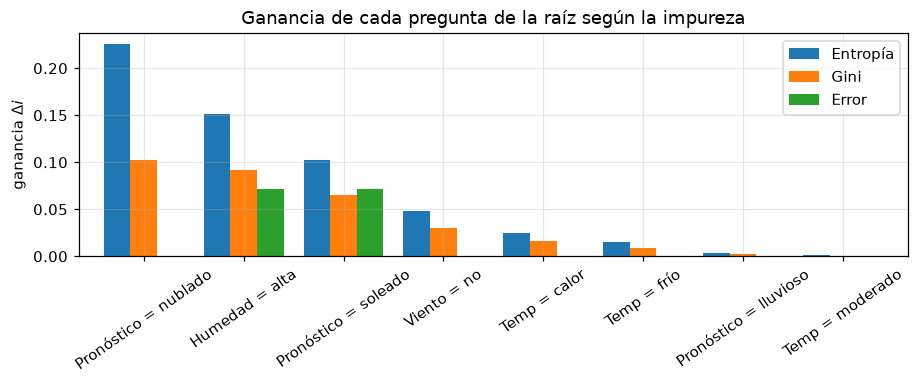

In [18]:
imps = {"entropia": "Entropía", "gini": "Gini", "error": "Error"}
cols = {}
for k, nombre in imps.items():
    _, res = evaluar(X1, y1, list(X1.columns), tipos1, k)
    cols[nombre] = {texto_pregunta(r["atributo"], r["tipo"], r["cond"]): r["ganancia"] for r in res}
comp_raiz = pd.DataFrame(cols).sort_values("Entropía", ascending=False)
display(comp_raiz.style.format("{:.4f}").highlight_max(axis=0, color="#d8ecd8"))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
comp_raiz.plot.bar(ax=ax, width=0.8)
ax.set(ylabel="ganancia $\\Delta i$", title="Ganancia de cada pregunta de la raíz según la impureza")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

**Observaciones.**

- **Gini** asigna ganancias distintas en valor pero **ordena las preguntas igual que la entropía**: nublado (0.1020) > humedad alta (0.0918) > soleado (0.0655) > viento > temperatura. Las dos son estrictamente cóncavas y tienen formas muy parecidas (figura del apartado 2.4), por lo que casi siempre eligen lo mismo.
- **El error de clasificación** se comporta distinto: asigna ganancia **cero a seis de las ocho preguntas**, incluida "Pronóstico = nublado", que era la mejor con las otras dos medidas. La razón es que, al separar las 4 muestras nubladas (todas P), el resto sigue teniendo 5 P y 5 N: la clase mayoritaria de cada hijo es P, la cantidad de errores sigue siendo 5 de 14 ($5/14$ antes y $\tfrac{4}{14}\cdot0+\tfrac{10}{14}\cdot0.5=5/14$ después). El error no "ve" que se obtuvo un nodo puro.
- Además hay un **empate en el primer puesto** entre Humedad = alta y Pronóstico = soleado, ambas con $0.0714$.

===== Entropía =====   hojas=7  prof=4  exactitud train=100%
¿Pronóstico = nublado?  [P=9, N=5]  Δi=0.2260
    sí: → P  [P=4, N=0]
    no: ¿Humedad = alta?  [P=5, N=5]  Δi=0.2781
        sí: ¿Pronóstico = lluvioso?  [P=1, N=4]  Δi=0.3219
            sí: ¿Viento = no?  [P=1, N=1]  Δi=1.0000
                sí: → P  [P=1, N=0]
                no: → N  [P=0, N=1]
            no: → N  [P=0, N=3]
        no: ¿Viento = no?  [P=4, N=1]  Δi=0.3219
            sí: → P  [P=3, N=0]
            no: ¿Pronóstico = lluvioso?  [P=1, N=1]  Δi=1.0000   (empate con: Temp = frío)
                sí: → N  [P=0, N=1]
                no: → P  [P=1, N=0]

===== Gini =====   hojas=7  prof=4  exactitud train=100%
¿Pronóstico = nublado?  [P=9, N=5]  Δi=0.1020
    sí: → P  [P=4, N=0]
    no: ¿Humedad = alta?  [P=5, N=5]  Δi=0.1800
        sí: ¿Pronóstico = lluvioso?  [P=1, N=4]  Δi=0.1200
            sí: ¿Viento = no?  [P=1, N=1]  Δi=0.5000
                sí: → P  [P=1, N=0]
                no: → N  [P=0, N=1]
 

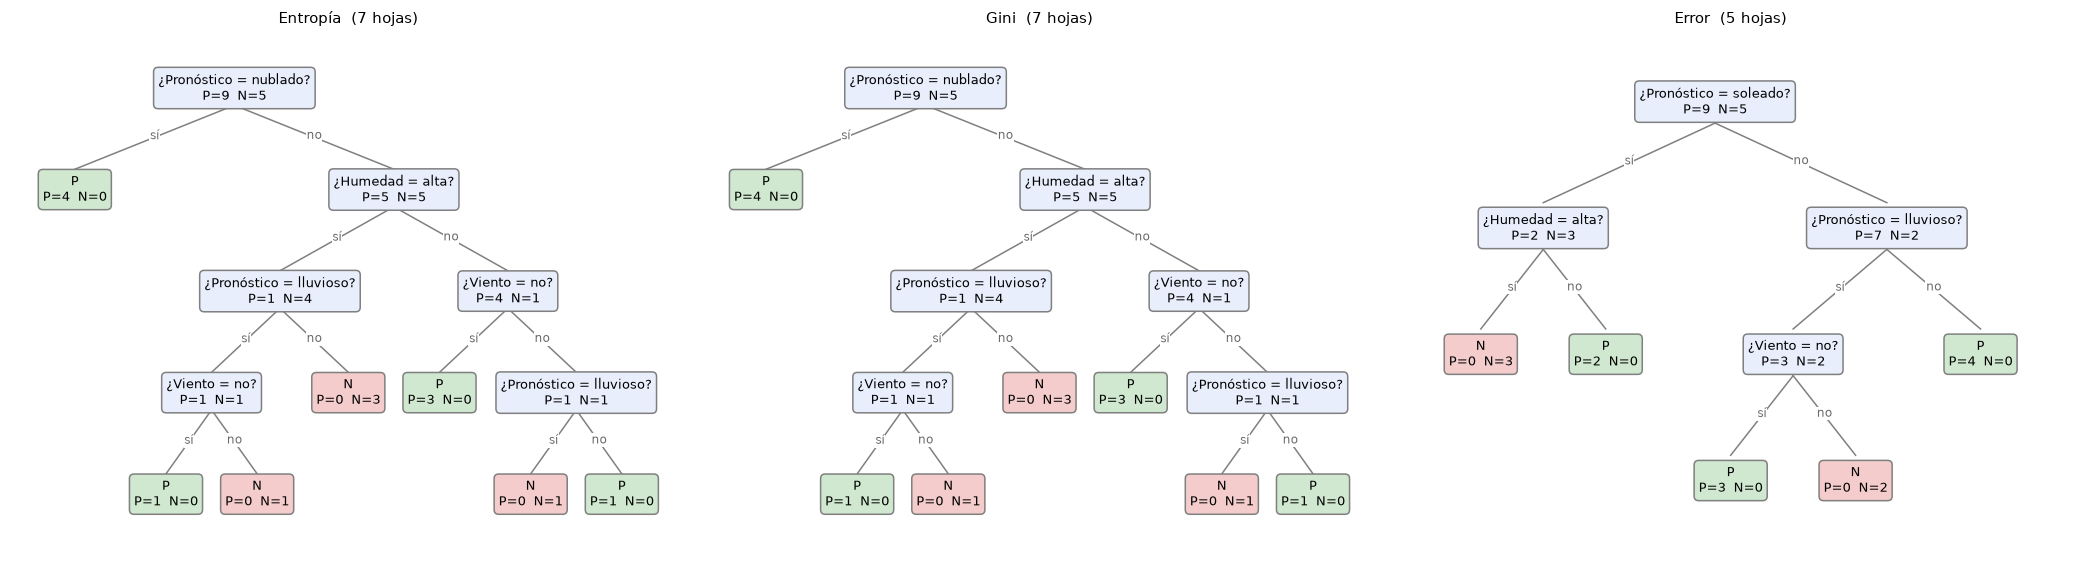

In [19]:
arboles = {k: ArbolBinario(k).fit(X1, y1, tipos1) for k in imps}
for k, a in arboles.items():
    print(f"===== {imps[k]} =====   hojas={hojas(a.raiz)}  prof={profundidad(a.raiz)}  exactitud train={exactitud(a, X1, y1):.0%}")
    imprimir(a.raiz)
    print()

print("¿Árbol con Gini idéntico al de entropía?       ", a_tupla(arboles['gini'].raiz) == a_tupla(arboles['entropia'].raiz))
print("¿Árbol con error de clasif. idéntico al de entropía?", a_tupla(arboles['error'].raiz) == a_tupla(arboles['entropia'].raiz))

fig, axs = plt.subplots(1, 3, figsize=(19, 5.2))
for ax, (k, a) in zip(axs, arboles.items()):
    dibujar_arbol(a.raiz, ax=ax, titulo=f"{imps[k]}  ({hojas(a.raiz)} hojas)")
plt.tight_layout(); plt.show()

**Observaciones.**

- **Gini** produce un árbol **idéntico** al de entropía (mismas preguntas, mismo orden, 7 hojas); solo difieren los valores numéricos de las ganancias.
- **Error de clasificación** produce un árbol **distinto**: la raíz es Pronóstico = soleado (por desempate con Humedad = alta) y tiene 5 hojas y profundidad 3 (es el árbol mínimo de la sección 4.4: soleado → humedad; no soleado → lluvioso → viento). Esto no significa que el error sea mejor impureza. Con el error, en el nodo "no soleado" (7 P y 2 N) **las seis preguntas posibles tienen ganancia cero** y el programa elige entre ellas por el orden de prioridad; coincide que la elegida (Pronóstico = lluvioso) es una buena pregunta.
- **Diferencia de fondo.** Entropía y Gini premian que los hijos queden **más puros**, aunque no cambie la cantidad de errores, y por eso encuentran preguntas útiles *para continuar* el árbol. El error de clasificación solo premia cuando cambia la clase mayoritaria de algún hijo; deja de ser informativo en cuanto una división mejora la pureza sin cambiar la clase mayoritaria, y entonces las decisiones se vuelven arbitrarias. Por esta razón, para **crecer** árboles se prefieren entropía o Gini; el error de clasificación se usa más bien para **podar**.

### Sensibilidad a los desempates

Como el error de clasificación produce **empates en la raíz**, el árbol resultante depende de la regla de desempate. Se repite la construcción con distintos órdenes de prioridad de los atributos y se mide cuántas hojas tiene el árbol y cómo generaliza según *leave-one-out* (entrenar con 13 muestras y predecir la que se dejó afuera). Con solo 14 datos este último número es muy ruidoso y sirve solo como referencia.

In [20]:
ordenes = {
    "Pron, Temp, Hum, Viento": ["Pronóstico", "Temp", "Humedad", "Viento"],
    "Hum, Pron, Temp, Viento": ["Humedad", "Pronóstico", "Temp", "Viento"],
    "Viento, Hum, Temp, Pron": ["Viento", "Humedad", "Temp", "Pronóstico"],
    "Temp, Viento, Pron, Hum": ["Temp", "Viento", "Pronóstico", "Humedad"],
}
filas_s = []
for k, nombre in imps.items():
    for o, pr in ordenes.items():
        crear = lambda k=k, pr=pr: ArbolBinario(k, prioridad=pr)
        a = crear().fit(X1, y1, tipos1)
        s0 = a.raiz["split"]
        filas_s.append({"Impureza": nombre, "Prioridad de atributos": o,
                        "Raíz": texto_pregunta(s0["atributo"], s0["tipo"], s0["cond"]),
                        "Empates en la raíz": len(s0["empates"]),
                        "Hojas": hojas(a.raiz), "Prof.": profundidad(a.raiz),
                        "Train": exactitud(a, X1, y1), "LOO": loo(crear, X1, y1, tipos1)})
sens = pd.DataFrame(filas_s)
display(sens.style.format({"Train": "{:.0%}", "LOO": "{:.1%}"}))

,Impureza,Prioridad de atributos,Raíz,Empates en la raíz,Hojas,Prof.,Train,LOO
0,Entropía,"Pron, Temp, Hum, Viento",Pronóstico = nublado,1,7,4,100%,50.0%
1,Entropía,"Hum, Pron, Temp, Viento",Pronóstico = nublado,1,7,4,100%,50.0%
2,Entropía,"Viento, Hum, Temp, Pron",Pronóstico = nublado,1,7,4,100%,57.1%
3,Entropía,"Temp, Viento, Pron, Hum",Pronóstico = nublado,1,7,4,100%,57.1%
4,Gini,"Pron, Temp, Hum, Viento",Pronóstico = nublado,1,7,4,100%,50.0%
5,Gini,"Hum, Pron, Temp, Viento",Pronóstico = nublado,1,7,4,100%,50.0%
6,Gini,"Viento, Hum, Temp, Pron",Pronóstico = nublado,1,7,4,100%,64.3%
7,Gini,"Temp, Viento, Pron, Hum",Pronóstico = nublado,1,7,4,100%,57.1%
8,Error,"Pron, Temp, Hum, Viento",Pronóstico = soleado,2,5,3,100%,71.4%
9,Error,"Hum, Pron, Temp, Viento",Humedad = alta,2,7,4,100%,71.4%


**Observaciones.**

- **Entropía y Gini son robustas al orden de prioridad:** en los cuatro órdenes dan árboles de 7 hojas y profundidad 4 con la misma raíz, porque tienen una mejor pregunta única en casi todos los nodos; el único empate (nodo 5) no cambia la forma del árbol, solo hace que esa última pregunta pueda ser Temp = frío en lugar de Pronóstico = lluvioso.
- **El error de clasificación depende mucho de los desempates**: según el orden, el árbol tiene entre 5 y 9 hojas y la raíz puede ser Pronóstico = soleado o Humedad = alta (empate). Es una consecuencia directa de las ganancias nulas y los empates comentados antes.
- **Sobre la columna LOO:** con 14 muestras, cada acierto o error cambia el resultado en $1/14\approx7$ puntos, así que las diferencias entre filas **no son significativas**. Lo que sí se puede decir es que **ningún árbol totalmente crecido generaliza bien**: casi todos quedan entre 50 % y 71 %, a la par o por debajo del clasificador trivial que siempre responde P (que en LOO acierta $9/14\approx64\%$). Los árboles completos memorizan los datos de entrenamiento (100 %) pero la muestra es demasiado chica para validar el modelo.

---
## 6. Inciso 2: atributos numéricos

El Cuadro 2 reemplaza la temperatura y la humedad categóricas por **valores numéricos** (temperatura y humedad relativa). El programa ya admite atributos numéricos: para cada uno, las preguntas candidatas son "$x \le t$" con $t$ el punto medio entre valores consecutivos distintos presentes **en el nodo**. Con $m$ valores distintos hay $m-1$ umbrales por atributo, y se los evalúa de la misma manera que a las particiones categóricas.

In [21]:
filas2 = [
    ("soleado", 85, 85, "no", "N"), ("soleado", 80, 90, "si", "N"), ("nublado", 83, 78, "no", "P"),
    ("lluvioso", 70, 96, "no", "P"), ("lluvioso", 68, 80, "no", "P"), ("lluvioso", 65, 70, "si", "N"),
    ("nublado", 64, 65, "si", "P"), ("soleado", 72, 95, "no", "N"), ("soleado", 69, 70, "no", "P"),
    ("lluvioso", 75, 80, "no", "P"), ("soleado", 75, 70, "si", "P"), ("nublado", 72, 90, "si", "P"),
    ("nublado", 81, 75, "no", "P"), ("lluvioso", 71, 80, "si", "N"),
]
df2 = pd.DataFrame(filas2, columns=["Pronóstico", "Temp", "Humedad", "Viento", "Juega"])
df2.index = np.arange(1, 15); df2.index.name = "#"
X2, y2 = df2.drop(columns="Juega"), df2["Juega"]
tipos2 = {"Pronóstico": "cat", "Temp": "num", "Humedad": "num", "Viento": "cat"}
display(df2)

for a in ["Temp", "Humedad"]:
    v = np.sort(X2[a].unique())
    print(f"{a}: {len(v)} valores distintos → {len(v)-1} umbrales posibles; "
          f"umbrales: {[float((u + w) / 2) for u, w in zip(v[:-1], v[1:])]}")

,Pronóstico,Temp,Humedad,Viento,Juega
#,,,,,
1,soleado,85,85,no,N
2,soleado,80,90,si,N
3,nublado,83,78,no,P
4,lluvioso,70,96,no,P
5,lluvioso,68,80,no,P
6,lluvioso,65,70,si,N
7,nublado,64,65,si,P
8,soleado,72,95,no,N
9,soleado,69,70,no,P


Temp: 12 valores distintos → 11 umbrales posibles; umbrales: [64.5, 66.5, 68.5, 69.5, 70.5, 71.5, 73.5, 77.5, 80.5, 82.0, 84.0]
Humedad: 9 valores distintos → 8 umbrales posibles; umbrales: [67.5, 72.5, 76.5, 79.0, 82.5, 87.5, 92.5, 95.5]


### 6.1 ¿Cuánto se parecen los datos numéricos a los categóricos?

Antes de construir el árbol conviene ver cómo se relacionan los valores del Cuadro 2 con las categorías del Cuadro 1: para cada categoría, qué rango de valores numéricos le corresponde.

In [22]:
cat_num = pd.concat([df[["Temp", "Humedad"]].add_suffix(" (cat.)"), df2[["Temp", "Humedad"]].add_suffix(" (num.)")], axis=1)
for a in ["Temp", "Humedad"]:
    g = cat_num.groupby(f"{a} (cat.)")[f"{a} (num.)"].agg(["min", "max", "count"])
    print(f"{a}: rango numérico por categoría")
    display(g)

Temp: rango numérico por categoría


,min,max,count
Temp (cat.),,,
calor,80,85,4
frío,64,69,4
moderado,70,75,6


Humedad: rango numérico por categoría


,min,max,count
Humedad (cat.),,,
alta,78,96,7
normal,65,80,7


**Observaciones.**

- **Temperatura:** la discretización es **monótona**: frío corresponde a 64 a 69, moderado a 70 a 75 y calor a 80 a 85. Los rangos no se solapan, así que "temperatura numérica" y "temperatura categórica" contienen la misma información.
- **Humedad:** *no* es monótona. "Alta" va de 78 a 96 y "normal" de 65 a 80, con rangos que se solapan (por ejemplo, las muestras 5 y 10 tienen humedad 80 y son "normal", mientras que la 14, también con 80, es "alta", y la 3, con 78, es "alta"). No existe ningún umbral numérico que reproduzca la partición alta/normal del Cuadro 1.
- **Consecuencia:** el árbol numérico no va a poder usar la humedad como la usó el categórico, que fue la pregunta clave del nodo 1.

### 6.2 Nodo raíz con atributos numéricos

Hay $3$ (pronóstico) $+\,1$ (viento) $+\,\text{umbrales de temp.}+\text{umbrales de humedad}$ preguntas. Se muestran las mejores:

In [23]:
i0_2, tabla_raiz2, res_raiz2 = tabla_candidatos(X2, y2, list(X2.columns), tipos2, "entropia", top=10)
print(f"Cantidad de preguntas evaluadas en la raíz: {len(res_raiz2)}")
display(tabla_raiz2.style.format({"i(sí)": "{:.4f}", "i(no)": "{:.4f}", "Δi": "{:.4f}"}))

Cantidad de preguntas evaluadas en la raíz: 23


,Pregunta (rama sí),sí (P/N),no (P/N),i(sí),i(no),Δi,máx
1,Pronóstico = nublado,4/0,5/5,0.0000,1.0000,0.2260,◀
2,Temp ≤ 84,9/4,0/1,0.8905,0.0000,0.1134,
3,Pronóstico = soleado,2/3,7/2,0.9710,0.7642,0.1022,
4,Humedad ≤ 82.5,7/2,2/3,0.7642,0.9710,0.1022,
5,Humedad ≤ 79,5/1,4/4,0.6500,1.0000,0.0903,
6,Viento = no,6/2,3/3,0.8113,1.0000,0.0481,
7,Temp ≤ 64.5,1/0,8/5,0.0000,0.9612,0.0477,
8,Humedad ≤ 67.5,1/0,8/5,0.0000,0.9612,0.0477,
9,Humedad ≤ 95.5,8/5,1/0,0.9612,0.0000,0.0477,
10,Temp ≤ 70.5,4/1,5/4,0.7219,0.9911,0.0453,


**Observaciones.** Se evalúan **23 preguntas** en la raíz (3 de pronóstico, 1 de viento, 11 umbrales de temperatura y 8 de humedad). La mejor sigue siendo **Pronóstico = nublado** ($0.2260$, el mismo valor que en el caso categórico, ya que no depende de los atributos numéricos). Los mejores umbrales numéricos quedan más abajo: Temp ≤ 84 ($0.1134$, aísla solo la muestra 1) y Humedad ≤ 82.5 ($0.1022$, empatada con Pronóstico = soleado).

¿Pronóstico = nublado?  [P=9, N=5]  Δi=0.2260
    sí: → P  [P=4, N=0]
    no: ¿Temp ≤ 77.5?  [P=5, N=5]  Δi=0.2365
        sí: ¿Temp ≤ 73.5?  [P=5, N=3]  Δi=0.2044
            sí: ¿Temp ≤ 70.5?  [P=3, N=3]  Δi=0.4591   (empate con: Viento = no)
                sí: ¿Temp ≤ 66.5?  [P=3, N=1]  Δi=0.8113   (empate con: Viento = no)
                    sí: → N  [P=0, N=1]
                    no: → P  [P=3, N=0]
                no: → N  [P=0, N=2]
            no: → P  [P=2, N=0]
        no: → N  [P=0, N=2]

Hojas: 6   Profundidad: 5   Exactitud en entrenamiento: 100%


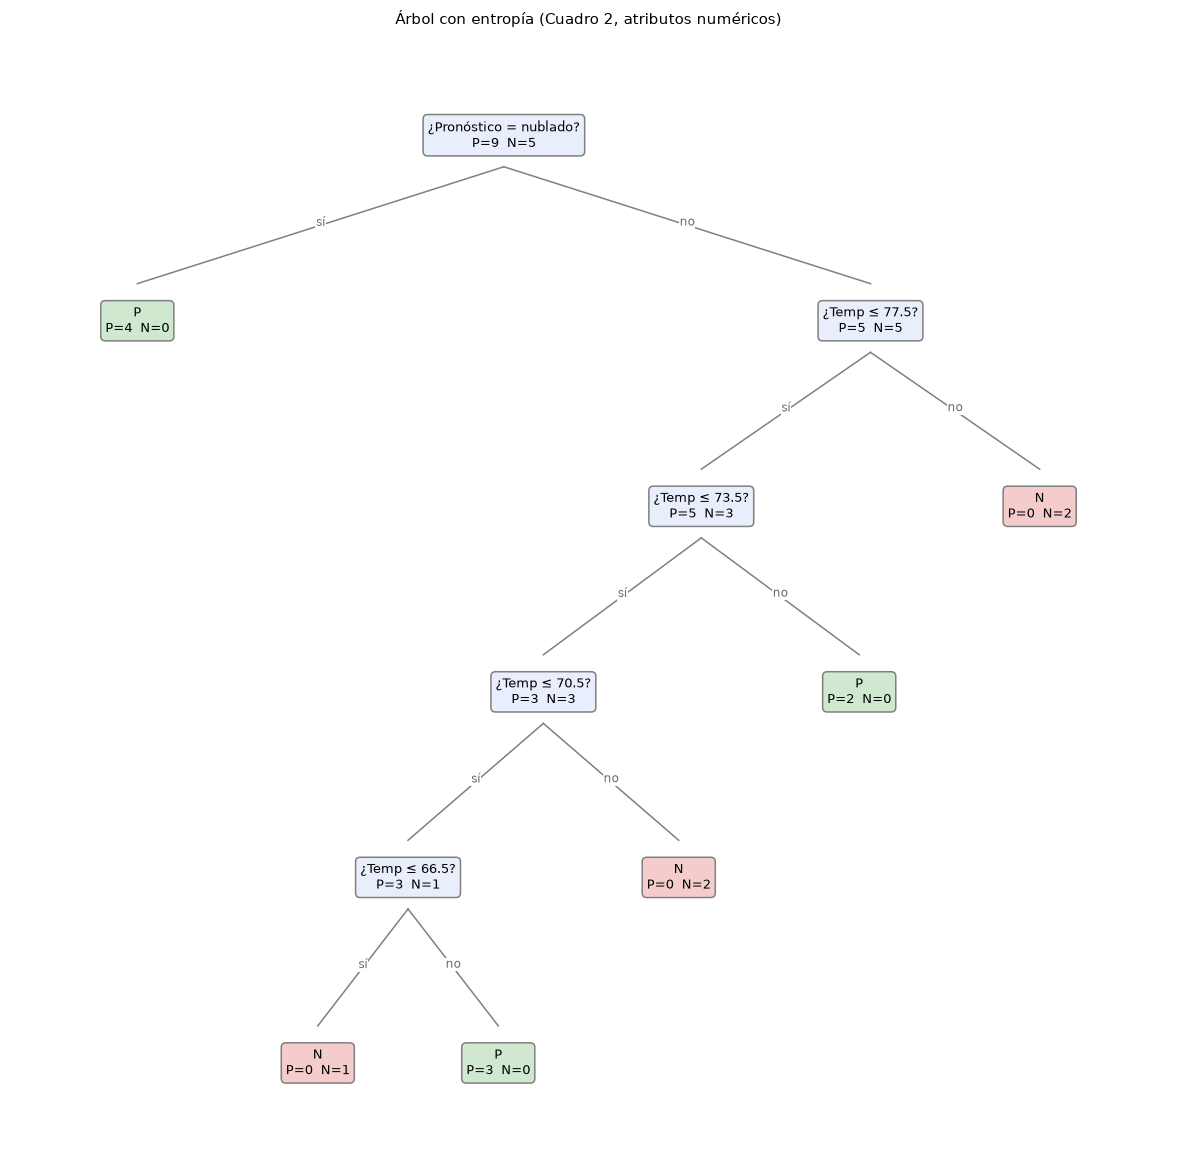

In [24]:
arbol_N = ArbolBinario("entropia").fit(X2, y2, tipos2)
imprimir(arbol_N.raiz)
print(f"\nHojas: {hojas(arbol_N.raiz)}   Profundidad: {profundidad(arbol_N.raiz)}   "
      f"Exactitud en entrenamiento: {exactitud(arbol_N, X2, y2):.0%}")
dibujar_arbol(arbol_N.raiz, titulo="Árbol con entropía (Cuadro 2, atributos numéricos)")
plt.tight_layout(); plt.show()

**Observaciones.**

- **Raíz y hoja izquierda:** igual que antes, "nublado" separa las 4 muestras P.
- **Nodo 1:** ahora gana **Temp ≤ 77.5** ($0.2365$), que aísla las dos muestras más calurosas (1 y 2, ambas N) de las otras 8 (5 P y 3 N). La cuenta es $1-\tfrac{8}{10}\cdot0.9544-\tfrac{2}{10}\cdot0=0.2365$. Humedad ya no aparece: sus mejores umbrales valen solo $0.1245$ en este nodo (frente a $0.2781$ de la humedad categórica).
- **Resto del árbol:** son cuatro preguntas consecutivas sobre la **temperatura** (77.5, 73.5, 70.5, 66.5) que van "pelando" las muestras. El árbol tiene **6 hojas** y profundidad 5, y clasifica bien las 14 muestras.
- **Empates:** en los nodos de Temp ≤ 70.5 y Temp ≤ 66.5 hay un empate de ganancia con **Viento = no**; son particiones distintas con los mismos conteos, y cualquiera es válida. Con el criterio de prioridad se elige la temperatura.

In [25]:
# Nodo 1 del árbol numérico: detalle de las cuentas de la mejor pregunta
n1b = X2[X2["Pronóstico"] != "nublado"]
y1b = y2[n1b.index]
print("Muestras del nodo (no nublado):", list(n1b.index), "  P/N:", conteos_de(y1b))
_, t1b, res1b = tabla_candidatos(n1b, y1b, list(X2.columns), tipos2, "entropia", top=6)
display(t1b.style.format({"i(sí)": "{:.4f}", "i(no)": "{:.4f}", "Δi": "{:.4f}"}))
detalle(res1b, "Temp ≤ 77.5")

Muestras del nodo (no nublado): [1, 2, 4, 5, 6, 8, 9, 10, 11, 14]   P/N: [5, 5]


,Pregunta (rama sí),sí (P/N),no (P/N),i(sí),i(no),Δi,máx
1,Temp ≤ 77.5,5/3,0/2,0.9544,0.0000,0.2365,◀
2,Temp ≤ 70.5,3/1,2/4,0.8113,0.9183,0.1245,
3,Humedad ≤ 82.5,4/2,1/3,0.9183,0.8113,0.1245,
4,Viento = no,4/2,1/3,0.9183,0.8113,0.1245,
5,Temp ≤ 66.5,0/1,5/4,0.0000,0.9911,0.1080,
6,Temp ≤ 82.5,5/4,0/1,0.9911,0.0000,0.1080,


Pregunta: Temp ≤ 77.5
  i(N)   = -(5/10·log2(5/10) + 5/10·log2(5/10)) = 1.0000
  i(sí)  = -(5/8·log2(5/8) + 3/8·log2(3/8)) = 0.9544      (8 muestras: P=5, N=3)
  i(no)  = -(2/2·log2(2/2)) = 0.0000      (2 muestras: P=0, N=2)
  Δi = i(N) - 8/10·i(sí) - 2/10·i(no) = 1.0000 - 0.8000·0.9544 - 0.2000·0.0000 = 0.2365


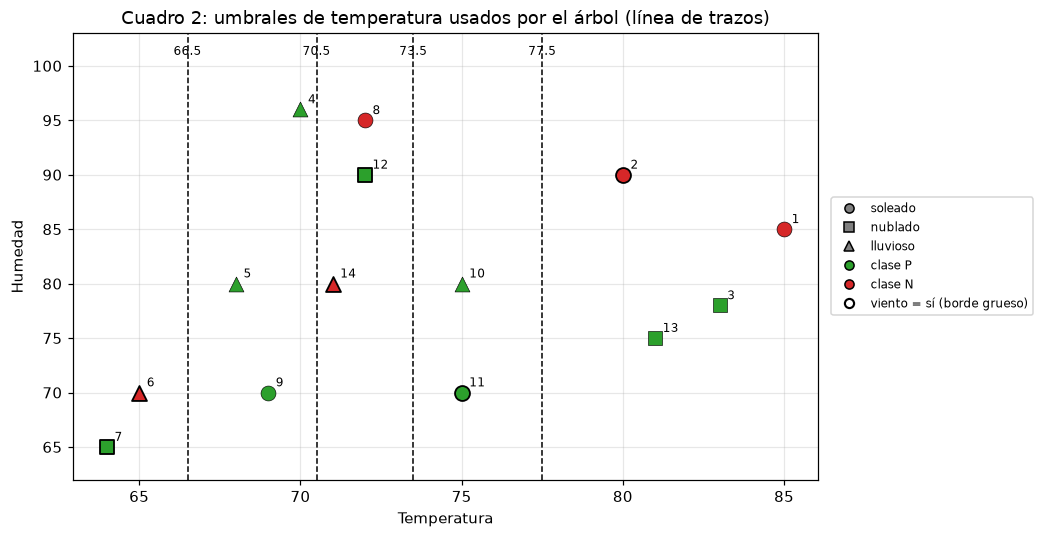

In [26]:
# Visualización: temperatura vs. humedad de las muestras del nodo "no nublado" y los umbrales de temperatura usados
def umbrales(n, a, acc=None):
    acc = [] if acc is None else acc
    if n["split"] is not None:
        if n["split"]["atributo"] == a:
            acc.append(n["split"]["cond"])
        umbrales(n["izq"], a, acc); umbrales(n["der"], a, acc)
    return acc


marc = {"soleado": "o", "nublado": "s", "lluvioso": "^"}
col = {"P": "tab:green", "N": "tab:red"}
fig, ax = plt.subplots(figsize=(9.6, 5))
for i, r in df2.iterrows():
    ax.scatter(r["Temp"], r["Humedad"], marker=marc[r["Pronóstico"]], c=col[r["Juega"]], s=95,
               edgecolor="k", linewidth=1.2 if r["Viento"] == "si" else 0.4, zorder=3)
    ax.annotate(str(i), (r["Temp"], r["Humedad"]), xytext=(5, 4), textcoords="offset points", fontsize=8)
for t in sorted(umbrales(arbol_N.raiz, "Temp")):
    ax.axvline(t, color="k", ls="--", lw=1)
    ax.text(t, 101, f"{t:g}", ha="center", fontsize=8)
ax.set(xlabel="Temperatura", ylabel="Humedad", ylim=(62, 103),
       title="Cuadro 2: umbrales de temperatura usados por el árbol (línea de trazos)")
from matplotlib.lines import Line2D
leg = [Line2D([], [], marker=m, ls="", c="gray", mec="k", label=k) for k, m in marc.items()]
leg += [Line2D([], [], marker="o", ls="", c=col[k], mec="k", label=f"clase {k}") for k in col]
leg += [Line2D([], [], marker="o", ls="", c="w", mec="k", mew=1.4, label="viento = sí (borde grueso)")]
ax.legend(handles=leg, fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(); plt.show()

**Observaciones.** Si se ordenan por temperatura las 10 muestras no nubladas, las clases se alternan así: N (65), P (68, 69, 70), N (71, 72), P (75, 75), N (80, 85). Es decir, **la temperatura no está monótonamente relacionada con la clase**: hay cuatro cambios de clase y el árbol necesita un umbral por cada uno (66.5, 70.5, 73.5 y 77.5, justo en los puntos medios de esos cambios). El resultado es un árbol profundo, que describe los datos con exactitud pero que difícilmente refleje una regla real: por ejemplo, afirma que, entre los días no nublados, 71 y 72 grados son malos para jugar, pero 70 y 75 son buenos.

### 6.3 Impurezas y desempates con atributos numéricos

===== Entropía =====   hojas=6  prof=5  exactitud train=100%
¿Pronóstico = nublado?  [P=9, N=5]  Δi=0.2260
    sí: → P  [P=4, N=0]
    no: ¿Temp ≤ 77.5?  [P=5, N=5]  Δi=0.2365
        sí: ¿Temp ≤ 73.5?  [P=5, N=3]  Δi=0.2044
            sí: ¿Temp ≤ 70.5?  [P=3, N=3]  Δi=0.4591   (empate con: Viento = no)
                sí: ¿Temp ≤ 66.5?  [P=3, N=1]  Δi=0.8113   (empate con: Viento = no)
                    sí: → N  [P=0, N=1]
                    no: → P  [P=3, N=0]
                no: → N  [P=0, N=2]
            no: → P  [P=2, N=0]
        no: → N  [P=0, N=2]

===== Gini =====   hojas=6  prof=5  exactitud train=100%
¿Pronóstico = nublado?  [P=9, N=5]  Δi=0.1020
    sí: → P  [P=4, N=0]
    no: ¿Temp ≤ 77.5?  [P=5, N=5]  Δi=0.1250
        sí: ¿Temp ≤ 66.5?  [P=5, N=3]  Δi=0.1116
            sí: → N  [P=0, N=1]
            no: ¿Temp ≤ 70.5?  [P=5, N=2]  Δi=0.1224
                sí: → P  [P=3, N=0]
                no: ¿Temp ≤ 73.5?  [P=2, N=2]  Δi=0.5000
                    sí: → N  [P=0

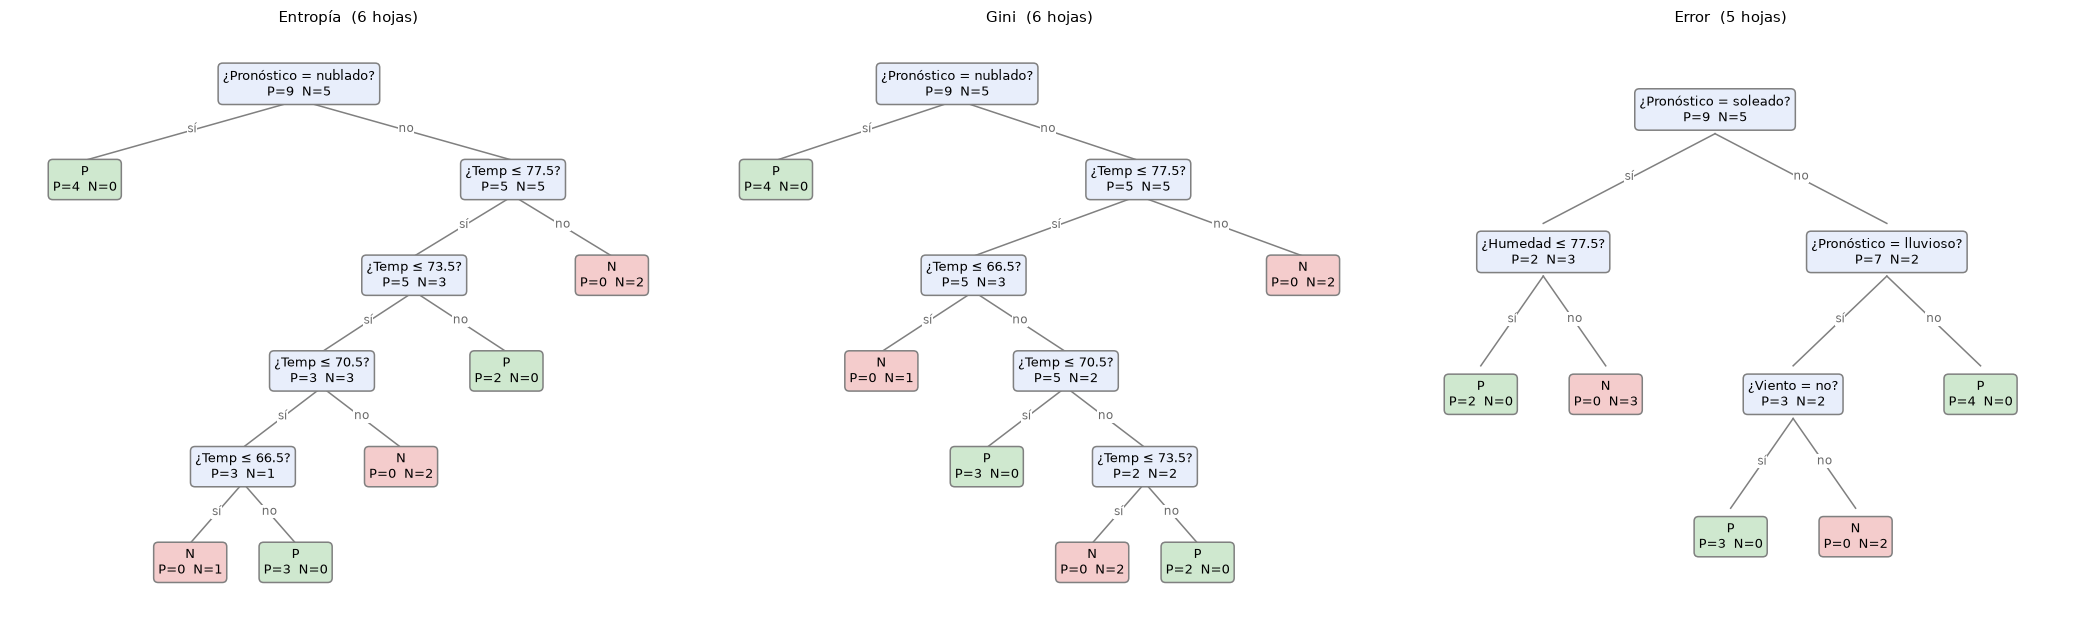

In [27]:
arboles2 = {k: ArbolBinario(k).fit(X2, y2, tipos2) for k in imps}
for k, a in arboles2.items():
    print(f"===== {imps[k]} =====   hojas={hojas(a.raiz)}  prof={profundidad(a.raiz)}  exactitud train={exactitud(a, X2, y2):.0%}")
    imprimir(a.raiz)
    print()
print("¿Gini idéntico a entropía?", a_tupla(arboles2['gini'].raiz) == a_tupla(arboles2['entropia'].raiz))

fig, axs = plt.subplots(1, 3, figsize=(19, 5.8))
for ax, (k, a) in zip(axs, arboles2.items()):
    dibujar_arbol(a.raiz, ax=ax, titulo=f"{imps[k]}  ({hojas(a.raiz)} hojas)")
plt.tight_layout(); plt.show()

**Observaciones.**

- **Gini vs. entropía:** los dos árboles tienen la misma raíz y la misma segunda pregunta (Temp ≤ 77.5), y luego usan **los mismos cuatro umbrales de temperatura pero en distinto orden** (entropía: 77.5, 73.5, 70.5, 66.5; Gini: 77.5, 66.5, 70.5, 73.5). Ambos tienen 6 hojas y profundidad 5, y definen **exactamente el mismo clasificador** (N hasta 66.5, P hasta 70.5, N hasta 73.5, P hasta 77.5 y N por encima), aunque las preguntas estén ordenadas distinto. Es un caso donde la impureza modifica el árbol, pero no la función que se aprende.
- **Error de clasificación:** otra vez un árbol más chico (5 hojas, profundidad 3) y con otra estructura: Pronóstico = soleado → Humedad ≤ 77.5 (umbral entre 70 y 85, elegido como punto medio), y no soleado → lluvioso → Viento. Es el análogo del árbol del caso categórico, con las mismas salvedades de empates y ganancias nulas.

In [28]:
filas_s2 = []
for k, nombre in imps.items():
    for o, pr in ordenes.items():
        crear = lambda k=k, pr=pr: ArbolBinario(k, prioridad=pr)
        a = crear().fit(X2, y2, tipos2)
        s0 = a.raiz["split"]
        filas_s2.append({"Impureza": nombre, "Prioridad de atributos": o,
                         "Raíz": texto_pregunta(s0["atributo"], s0["tipo"], s0["cond"]),
                         "Hojas": hojas(a.raiz), "Prof.": profundidad(a.raiz),
                         "Train": exactitud(a, X2, y2), "LOO": loo(crear, X2, y2, tipos2)})
display(pd.DataFrame(filas_s2).style.format({"Train": "{:.0%}", "LOO": "{:.1%}"}))

,Impureza,Prioridad de atributos,Raíz,Hojas,Prof.,Train,LOO
0,Entropía,"Pron, Temp, Hum, Viento",Pronóstico = nublado,6,5,100%,50.0%
1,Entropía,"Hum, Pron, Temp, Viento",Pronóstico = nublado,6,5,100%,42.9%
2,Entropía,"Viento, Hum, Temp, Pron",Pronóstico = nublado,6,5,100%,50.0%
3,Entropía,"Temp, Viento, Pron, Hum",Pronóstico = nublado,6,5,100%,42.9%
4,Gini,"Pron, Temp, Hum, Viento",Pronóstico = nublado,6,5,100%,42.9%
5,Gini,"Hum, Pron, Temp, Viento",Pronóstico = nublado,6,5,100%,35.7%
6,Gini,"Viento, Hum, Temp, Pron",Pronóstico = nublado,6,5,100%,42.9%
7,Gini,"Temp, Viento, Pron, Hum",Pronóstico = nublado,6,5,100%,35.7%
8,Error,"Pron, Temp, Hum, Viento",Pronóstico = soleado,5,3,100%,42.9%
9,Error,"Hum, Pron, Temp, Viento",Humedad ≤ 82.5,7,5,100%,50.0%


**Observaciones.**

- Entropía y Gini mantienen 6 hojas y profundidad 5 con cualquier prioridad, y el error de clasificación vuelve a depender fuertemente de los desempates: con la prioridad "Temp, Viento, Pron, Hum" la raíz pasa a ser **Temp ≤ 84** y el árbol llega a **10 hojas** y profundidad 8, casi una hoja por muestra.
- La exactitud leave-one-out es baja (entre 36 % y 50 % en todos los casos), por debajo del clasificador trivial (64 %). Igual que en el caso categórico, **14 muestras no alcanzan para validar** estos árboles; lo que muestra la tabla es que cuando se agrega información numérica sin más control, el árbol crece hasta ajustar cada muestra (sobreajuste).
- Para obtener árboles que generalicen sería necesario **limitar su tamaño** (`max_prof`, `min_muestras_div`, `min_ganancia`, que el programa ya admite) o **podarlos** y elegir esos hiperparámetros con más datos y validación cruzada.

---
## 7. Conclusiones

1. **Construcción.** Un árbol binario se crece de forma voraz: en cada nodo se evalúan todas las preguntas binarias posibles (particiones del conjunto de valores para atributos categóricos; umbrales entre valores consecutivos para los numéricos) y se elige la de mayor reducción de impureza. Para el Cuadro 1 el resultado es un árbol de 7 hojas y profundidad 4 que clasifica bien las 14 muestras: raíz "Pronóstico = nublado", luego humedad, y después pronóstico/viento. El programa lo reproduce exactamente, y también coincide con `scikit-learn` (misma pregunta en la raíz, ganancia $0.2260$, mismas predicciones).
2. **Empates.** Solo hay un empate en el árbol categórico (nodo 5: pronóstico o temperatura); en los casos con empates el resultado depende de la regla de desempate, por lo que conviene registrarlos y ser explícito con la regla usada.
3. **Restricción binaria.** Con tres valores por atributo, dividir en un solo paso por pronóstico habría dado más ganancia ($0.2467$ vs. $0.2260$); con preguntas binarias el mismo refinamiento se hace en dos pasos.
4. **Voraz no es óptimo.** El mínimo posible es 5 hojas y el árbol voraz tiene 7. La pérdida no está en la raíz sino en el nodo 1, donde la pregunta con mejor ganancia inmediata (humedad) lleva a un subárbol mayor que la de ganancia casi nula (Pronóstico = lluvioso).
5. **Elección de la impureza.** Entropía y Gini son prácticamente equivalentes: dan el mismo árbol en el Cuadro 1 y definen el mismo clasificador en el Cuadro 2 (con otro orden de preguntas). El error de clasificación es poco sensible: asigna ganancia cero a divisiones que dejan nodos más puros, genera empates y su resultado depende del desempate (de 5 a 9 hojas en el Cuadro 1, hasta 10 en el Cuadro 2). Por eso se usa para podar más que para crecer.
6. **Atributos numéricos.** El tratamiento con umbrales es directo, pero la información numérica puede ser mucho más ruidosa que la categórica: aquí la temperatura se relaciona con la clase de forma no monótona, y el árbol necesita cuatro umbrales consecutivos sobre la misma variable; además la humedad numérica no reproduce la partición alta/normal, así que deja de ser útil en el nodo 1.
7. **Generalización.** Los árboles crecidos hasta nodos puros ajustan los datos de entrenamiento al 100 % pero, con tan pocas muestras, su exactitud leave-one-out no supera la de predecir siempre "P". Para que un árbol generalice hay que **controlar su complejidad** (profundidad máxima, mínimo de muestras, poda) y validar con más datos.